
<div style="background:#1f4e78;color:white;padding:18px;border-radius:10px;text-align:center">
<h1 style="margin:0;">MODELO SIR MCMC</h1>
<h2 style="margin:8px 0 0 0;">Ajuste de parámetros y comparación visual con el artículo</h2>
<h3 style="margin:8px 0 0 0;">Simulación II</h3>
</div>



## 1. Planteamiento del problema

El modelo **SIR** divide a una población en tres grupos:

- $S(t)$: personas susceptibles.
- $I(t)$: personas infectadas.
- $R(t)$: personas removidas o recuperadas.

El sistema de ecuaciones diferenciales utilizado es:

$$
\frac{dS}{dt}=-aSI
$$

$$
\frac{dI}{dt}=aSI-bI
$$

$$
\frac{dR}{dt}=bI
$$

donde:

- $a$ representa la **tasa de transmisión**.
- $b$ representa la **tasa promedio de recuperación**.

La población total permanece constante:

$$
N=S(t)+I(t)+R(t)
$$

El objetivo es encontrar los valores de $a$ y $b$ que hacen que la solución numérica del modelo se aproxime lo mejor posible a los datos observados de infectados.



## 2. Datos del problema

Se utiliza el ejemplo **Influenza in a boarding school** presentado en el artículo proporcionado.

La población total es:

$$
N=763
$$

Las condiciones iniciales son:

$$
S(0)=762,\qquad I(0)=1,\qquad R(0)=0
$$

Los datos observados de infectados son:

$$
I_{\mathrm{datos}}=
[1,3,6,25,73,222,294,258,237,191,125,69,27,11,4]
$$

para los tiempos:

$$
t=0,1,\ldots,14.
$$


In [1]:
# Importamos las bibliotecas necesarias.
# numpy: operaciones numéricas y manejo de arreglos.
# matplotlib: elaboración de gráficas.
# solve_ivp: solución numérica del sistema de ecuaciones diferenciales.
# mpimg: lectura de imágenes para incrustarlas en el cuaderno.

import os

# Indicamos a Matplotlib una carpeta local con permisos de escritura.
# Esto evita que aparezcan mensajes de advertencia al iniciar.
os.environ["MPLCONFIGDIR"] = os.path.join(os.getcwd(), ".matplotlib")
os.makedirs(os.environ["MPLCONFIGDIR"], exist_ok=True)

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from scipy.integrate import solve_ivp

# Semilla para que los resultados puedan reproducirse.
SEMILLA = 2026


## 3. Datos observados

En Python utilizamos arreglos de `numpy` para guardar los tiempos y el número de infectados observado.


In [2]:
# Tiempo de observación: días 0 a 14.
t_datos = np.arange(15, dtype=float)

# Número de infectados reportados en cada día.
I_datos = np.array(
    [1, 3, 6, 25, 73, 222, 294, 258, 237, 191, 125, 69, 27, 11, 4],
    dtype=float
)

# Población total y condiciones iniciales.
N = 763.0
S0 = 762.0
I0 = 1.0
R0 = 0.0
y0 = [S0, I0, R0]

print("Población total:", int(N))
print("Número de observaciones:", len(I_datos))


Población total: 763
Número de observaciones: 15



## 4. Solución numérica del modelo SIR

Para cada par de parámetros $(a,b)$ necesitamos resolver el sistema SIR.

La función `solve_ivp()` integra numéricamente las ecuaciones diferenciales y devuelve los valores de $S(t)$, $I(t)$ y $R(t)$.


In [3]:
def simular_sir(a, b, tiempos=t_datos):
    """Resuelve numéricamente el sistema SIR para un par de parámetros (a, b)."""

    def sistema_sir(t, y):
        # Desempaquetamos las tres variables de estado.
        S, I, R = y

        # Ecuaciones diferenciales del modelo SIR.
        dS = -a * S * I
        dI =  a * S * I - b * I
        dR =  b * I

        return [dS, dI, dR]

    solucion = solve_ivp(
        sistema_sir,
        (tiempos[0], tiempos[-1]),
        y0,
        t_eval=tiempos,
        rtol=1e-6,
        atol=1e-8
    )

    return solucion.y[0], solucion.y[1], solucion.y[2]



## 5. Función de distancia

Siguiendo el criterio mostrado en clase y empleado en el artículo, medimos la diferencia entre la simulación y los datos mediante la **distancia Manhattan o norma $L_1$**:

$$
d_i=\left|I_{\mathrm{sim}}(t_i)-I_{\mathrm{datos}}(t_i)\right|
$$

y la distancia total es:

$$
D(a,b)=\sum_{i=1}^{n}d_i
$$

Mientras menor sea $D(a,b)$, mejor es el ajuste.


In [4]:
def distancia_L1(a, b):
    """Calcula la suma de errores absolutos entre el modelo y los datos."""

    # El artículo considera a y b dentro del intervalo (0, 1).
    if not (0 < a < 1 and 0 < b < 1):
        return np.inf

    _, I_sim, _ = simular_sir(a, b)

    # np.abs obtiene el valor absoluto elemento por elemento.
    # np.sum suma todas las diferencias.
    return np.sum(np.abs(I_sim - I_datos))



## 6. Metropolis-Hastings para ajustar $a$ y $b$

El artículo resuelve el problema inverso con un algoritmo genético. En esta actividad se conserva el mismo modelo SIR, los mismos datos y la misma distancia $L_1$, pero el ajuste se realiza mediante **MCMC con Metropolis-Hastings**.

Para usar la distancia dentro de Metropolis-Hastings definimos una distribución objetivo proporcional a:

$$
\pi(a,b)\propto
\exp\left(-\frac{D(a,b)}{\tau}\right),
\qquad 0<a<1,\;0<b<1
$$

donde $\tau$ controla qué tan fácilmente se aceptan propuestas con mayor error.

En cada iteración:

1. Partimos del estado actual $(a,b)$.
2. Proponemos un nuevo par $(a',b')$ mediante una caminata aleatoria normal.
3. Calculamos $D(a',b')$.
4. Aceptamos la propuesta con probabilidad:

$$
\alpha=
\min\left(
1,
\exp\left[-\frac{D(a',b')-D(a,b)}{\tau}\right]
\right).
$$

Una solución con menor distancia se acepta siempre; una peor todavía puede aceptarse con cierta probabilidad, lo que permite explorar el espacio de parámetros.


In [5]:
def metropolis_hastings(
    n_iteraciones=12000,
    calentamiento=2000,
    temperatura=12.0,
    sigma_a=8e-5,
    sigma_b=0.015,
    semilla=SEMILLA
):
    """Ajusta a y b mediante una caminata Metropolis-Hastings."""

    rng = np.random.default_rng(semilla)

    # Punto inicial razonable dentro del espacio permitido.
    a_actual = 0.0022
    b_actual = 0.45
    D_actual = distancia_L1(a_actual, b_actual)

    # Cada fila guardará: a, b y distancia.
    cadena = np.zeros((n_iteraciones, 3))

    mejor_a = a_actual
    mejor_b = b_actual
    mejor_D = D_actual

    aceptados = 0

    for i in range(n_iteraciones):

        # Propuesta de caminata aleatoria.
        a_propuesto = a_actual + rng.normal(0, sigma_a)
        b_propuesto = b_actual + rng.normal(0, sigma_b)

        # Solo evaluamos propuestas dentro de (0, 1).
        if 0 < a_propuesto < 1 and 0 < b_propuesto < 1:

            D_propuesto = distancia_L1(a_propuesto, b_propuesto)

            # Regla de aceptación de Metropolis-Hastings.
            alpha = min(
                1.0,
                np.exp(-(D_propuesto - D_actual) / temperatura)
            )

            if rng.random() < alpha:
                a_actual = a_propuesto
                b_actual = b_propuesto
                D_actual = D_propuesto
                aceptados += 1

                # Guardamos también la mejor solución encontrada.
                if D_actual < mejor_D:
                    mejor_a = a_actual
                    mejor_b = b_actual
                    mejor_D = D_actual

        cadena[i] = [a_actual, b_actual, D_actual]

    tasa_aceptacion = aceptados / n_iteraciones

    return cadena, (mejor_a, mejor_b, mejor_D), tasa_aceptacion, calentamiento



## 7. Ejecución del MCMC

Se utilizan **12 000 iteraciones** y se descartan las primeras **2 000** como periodo de calentamiento (*burn-in*).

El *burn-in* permite retirar la parte inicial de la cadena antes de analizar los parámetros.


In [6]:
cadena, mejor, tasa_aceptacion, burn_in = metropolis_hastings()

mejor_a, mejor_b, mejor_D = mejor

posterior = cadena[burn_in:]

a_promedio = posterior[:, 0].mean()
b_promedio = posterior[:, 1].mean()

# Guardamos la evolución de la distancia para analizar cómo mejora el ajuste.
D_hist = cadena[:, 2]
D_mejor_acumulada = np.minimum.accumulate(D_hist)
D_promedio_acumulado = np.cumsum(D_hist) / np.arange(1, len(D_hist) + 1)

print("--- RESULTADOS DEL AJUSTE MCMC ---")
print(f"Mejor a encontrado: {mejor_a:.6f}")
print(f"Mejor b encontrado: {mejor_b:.6f}")
print(f"Distancia L1 mínima: {mejor_D:.3f}")
print(f"Promedio posterior de a: {a_promedio:.6f}")
print(f"Promedio posterior de b: {b_promedio:.6f}")
print(f"Tasa de aceptación: {tasa_aceptacion:.2%}")

--- RESULTADOS DEL AJUSTE MCMC ---
Mejor a encontrado: 0.002161
Mejor b encontrado: 0.423630
Distancia L1 mínima: 210.860
Promedio posterior de a: 0.002184
Promedio posterior de b: 0.443974
Tasa de aceptación: 35.76%



## 8. Gráfica de los datos y del mejor ajuste

La siguiente gráfica permite comparar directamente los infectados observados con la curva de infectados producida por el mejor par $(a,b)$ encontrado por MCMC.


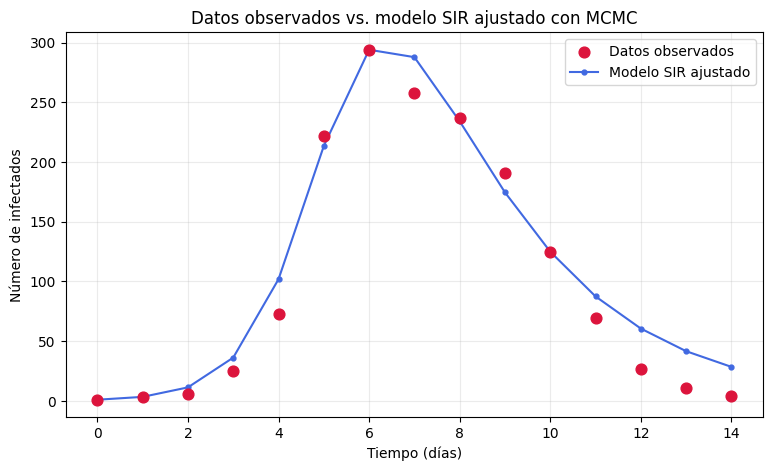

In [7]:
S_mejor, I_mejor, R_mejor = simular_sir(mejor_a, mejor_b)

plt.figure(figsize=(9, 5))

# Datos reales: puntos rojos.
plt.scatter(
    t_datos, I_datos,
    color="crimson",
    s=60,
    marker="o",
    label="Datos observados",
    zorder=4
)

# Modelo SIR: línea azul con marcadores pequeños.
plt.plot(
    t_datos, I_mejor,
    color="royalblue",
    linestyle="-",
    linewidth=1.5,
    marker="o",
    markersize=3.5,
    label="Modelo SIR ajustado"
)

plt.xlabel("Tiempo (días)")
plt.ylabel("Número de infectados")
plt.title("Datos observados vs. modelo SIR ajustado con MCMC")
plt.grid(alpha=0.25)
plt.legend()
plt.show()


## 9. Comportamiento completo del modelo SIR

Con los parámetros obtenidos podemos observar la evolución de susceptibles, infectados y removidos.


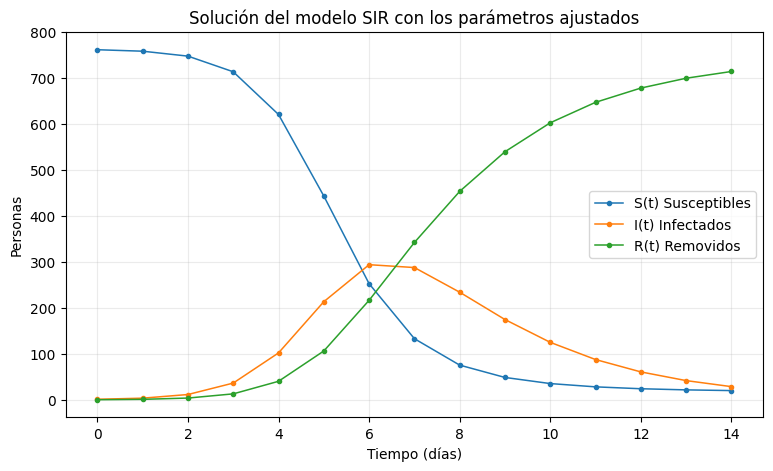

In [8]:
plt.figure(figsize=(9, 5))

plt.plot(t_datos, S_mejor, marker="o", markersize=3, linewidth=1.1, label="S(t) Susceptibles")
plt.plot(t_datos, I_mejor, marker="o", markersize=3, linewidth=1.1, label="I(t) Infectados")
plt.plot(t_datos, R_mejor, marker="o", markersize=3, linewidth=1.1, label="R(t) Removidos")

plt.xlabel("Tiempo (días)")
plt.ylabel("Personas")
plt.title("Solución del modelo SIR con los parámetros ajustados")
plt.grid(alpha=0.25)
plt.legend()
plt.show()


## 10. Revisión de la cadena MCMC

Una forma sencilla de revisar el comportamiento del algoritmo es observar la trayectoria de cada parámetro durante las iteraciones.


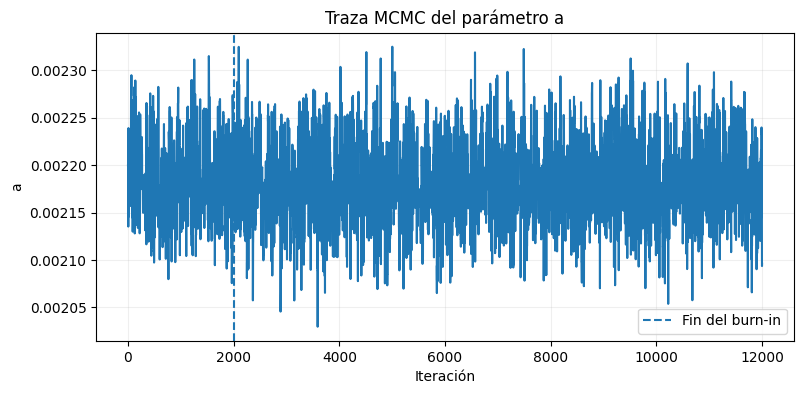

In [9]:
plt.figure(figsize=(9, 4))
plt.plot(cadena[:, 0])
plt.axvline(burn_in, linestyle="--", label="Fin del burn-in")
plt.xlabel("Iteración")
plt.ylabel("a")
plt.title("Traza MCMC del parámetro a")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


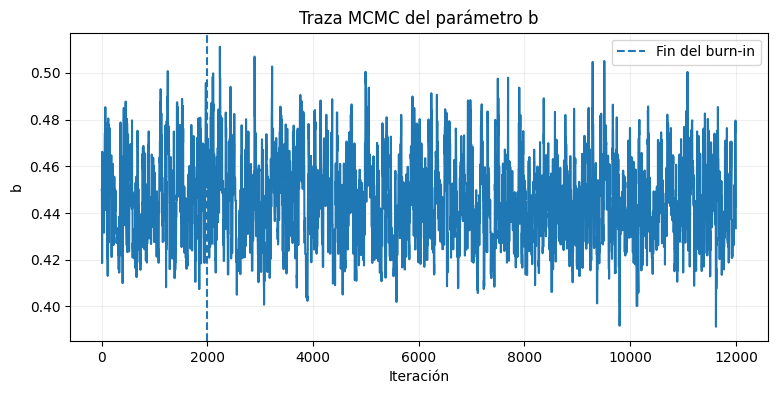

In [10]:
plt.figure(figsize=(9, 4))
plt.plot(cadena[:, 1])
plt.axvline(burn_in, linestyle="--", label="Fin del burn-in")
plt.xlabel("Iteración")
plt.ylabel("b")
plt.title("Traza MCMC del parámetro b")
plt.legend()
plt.grid(alpha=0.2)
plt.show()



## 11. Exploración conjunta de los parámetros

Los puntos siguientes representan pares $(a,b)$ visitados después del periodo de calentamiento.


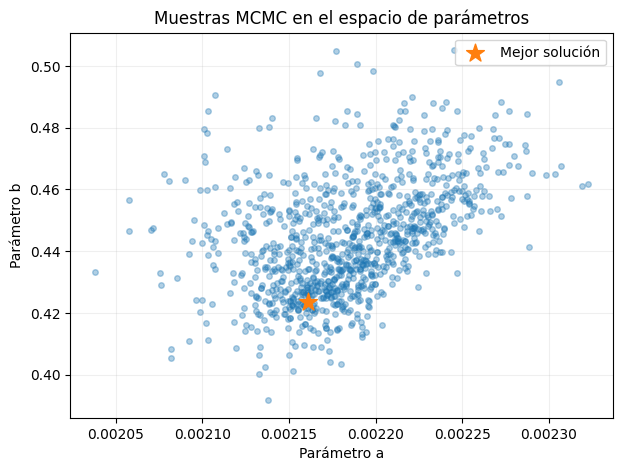

In [11]:
# Tomamos uno de cada 10 puntos para que la gráfica sea más clara.
muestra = posterior[::10]

plt.figure(figsize=(7, 5))
plt.scatter(muestra[:, 0], muestra[:, 1], alpha=0.35, s=16)
plt.scatter([mejor_a], [mejor_b], marker="*", s=180, label="Mejor solución")
plt.xlabel("Parámetro a")
plt.ylabel("Parámetro b")
plt.title("Muestras MCMC en el espacio de parámetros")
plt.legend()
plt.grid(alpha=0.2)
plt.show()



## 12. Comparación visual real: artículo vs. reajuste MCMC

En esta sección **sí se muestran directamente las gráficas**, no solamente el código.

Primero se coloca la gráfica del artículo y, a su lado, la gráfica obtenida con el nuevo ajuste MCMC para que la comparación sea visual.


### 12.1 Ajuste de infectados: artículo vs. MCMC

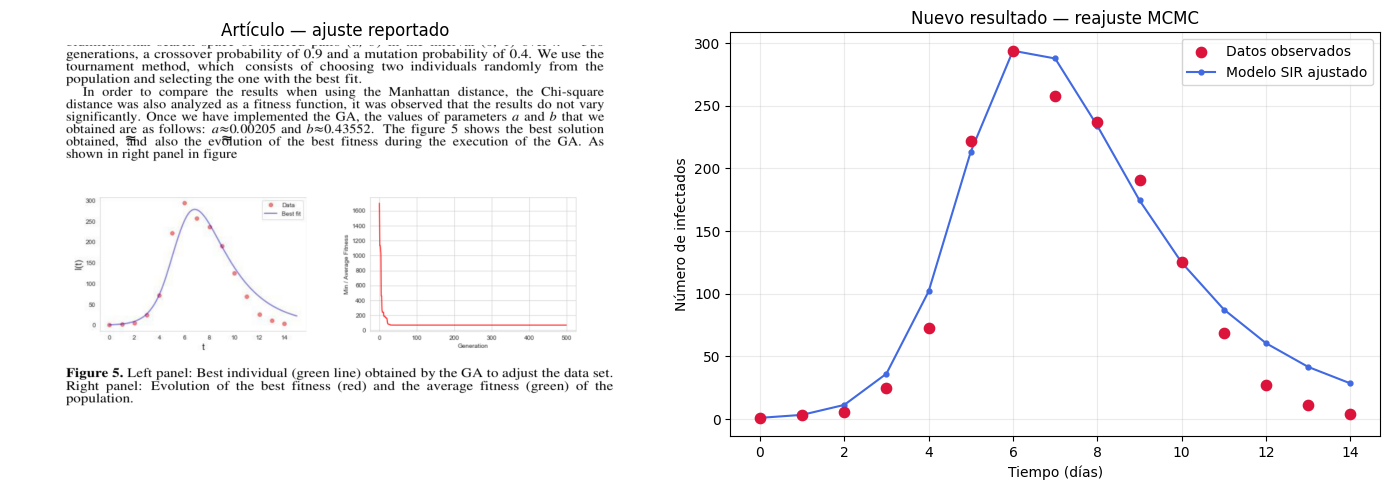

In [12]:
# Comparación del ajuste de infectados: artículo vs. reajuste MCMC.

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

try:
    img_ajuste = mpimg.imread("/mnt/data/articulo_figura5_ajuste.png")
    axes[0].imshow(img_ajuste)
    axes[0].axis("off")
    axes[0].set_title("Artículo — ajuste reportado")
except Exception:
    axes[0].text(
        0.5, 0.5,
        "Figura de referencia del artículo\n(ver Figura 5 del material)",
        ha="center", va="center", fontsize=13
    )
    axes[0].axis("off")
    axes[0].set_title("Artículo — ajuste reportado")

axes[1].scatter(
    t_datos, I_datos,
    color="crimson",
    s=55,
    label="Datos observados",
    zorder=4
)

axes[1].plot(
    t_datos, I_mejor,
    color="royalblue",
    linewidth=1.5,
    marker="o",
    markersize=3.5,
    label="Modelo SIR ajustado"
)

axes[1].set_xlabel("Tiempo (días)")
axes[1].set_ylabel("Número de infectados")
axes[1].set_title("Nuevo resultado — reajuste MCMC")
axes[1].grid(alpha=0.25)
axes[1].legend()

plt.tight_layout()
plt.show()

**Interpretación:** la gráfica de la izquierda corresponde a la Figura 5 del artículo, donde se compara el ajuste obtenido con el método reportado por los autores. La gráfica de la derecha muestra nuestro reajuste con MCMC. Para que la comparación visual sea más clara, los **datos observados** se muestran en color **rojo** y la **curva ajustada** se muestra como una línea **azul punteada con marcadores**.


### 12.2 Evolución de la función de ajuste durante MCMC

En el artículo se muestra cómo disminuye el **fitness** conforme avanzan las generaciones del algoritmo genético.

En nuestro caso no existe una población de individuos en cada generación, porque **MCMC trabaja con una cadena de estados**. Para construir una gráfica equivalente usamos la misma medida de error del ejercicio:

$$
D(a,b)=\sum_{i=1}^{n}\left|I_{\mathrm{sim}}(t_i)-I_{\mathrm{datos}}(t_i)\right|
$$

A partir de la cadena calculamos:

$$
D_{\min}(k)=\min\{D_1,D_2,\ldots,D_k\}
$$

que representa la **mejor distancia encontrada hasta la iteración $k$**, y

$$
\bar D(k)=\frac{1}{k}\sum_{j=1}^{k}D_j
$$

que representa la **distancia promedio acumulada**.

Una disminución de $D_{\min}$ indica que el algoritmo está encontrando parámetros que ajustan mejor los datos.


Distancia inicial: 222.26
Mejor distancia final: 210.86
Promedio acumulado final: 227.36


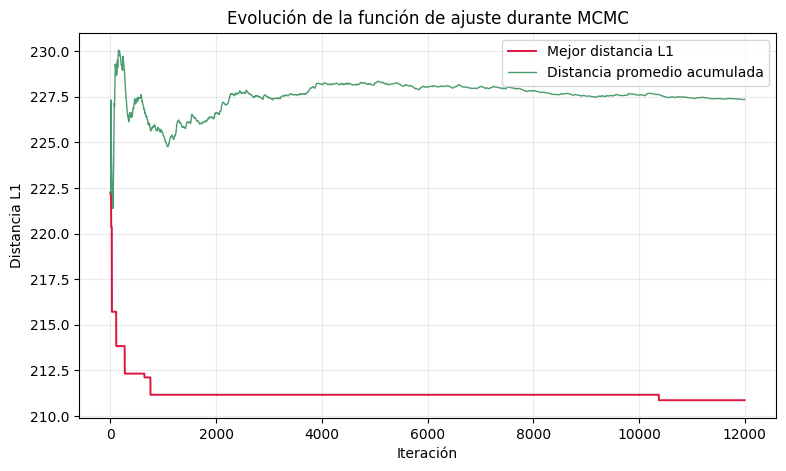

In [13]:
# Calculamos la evolución de la función de ajuste usando los valores
# de distancia L1 almacenados en cada paso de la cadena MCMC.

distancias = cadena[:, 2]

# Mejor distancia obtenida hasta cada iteración.
mejor_distancia = np.minimum.accumulate(distancias)

# Promedio acumulado de la distancia.
promedio_distancia = np.cumsum(distancias) / np.arange(1, len(distancias) + 1)

print(f"Distancia inicial: {distancias[0]:.2f}")
print(f"Mejor distancia final: {mejor_distancia[-1]:.2f}")
print(f"Promedio acumulado final: {promedio_distancia[-1]:.2f}")

plt.figure(figsize=(9, 5))

# Línea roja equivalente al mejor fitness del artículo.
plt.plot(
    mejor_distancia,
    color="crimson",
    linewidth=1.4,
    label="Mejor distancia L1"
)

# Línea verde para el comportamiento promedio.
plt.plot(
    promedio_distancia,
    color="seagreen",
    linewidth=1.0,
    alpha=0.85,
    label="Distancia promedio acumulada"
)

plt.xlabel("Iteración")
plt.ylabel("Distancia L1")
plt.title("Evolución de la función de ajuste durante MCMC")
plt.grid(alpha=0.25)
plt.legend()
plt.show()


**Interpretación:** la línea roja representa el mejor valor de la distancia $L_1$ encontrado hasta cada iteración. Al principio el error es mayor y después disminuye hasta estabilizarse. La línea verde muestra el comportamiento promedio de las distancias visitadas por la cadena. Esta gráfica cumple una función similar a la gráfica de evolución del *fitness* presentada en el artículo, pero adaptada correctamente al método MCMC.


### 12.3 Dinámica SIR: artículo vs. MCMC

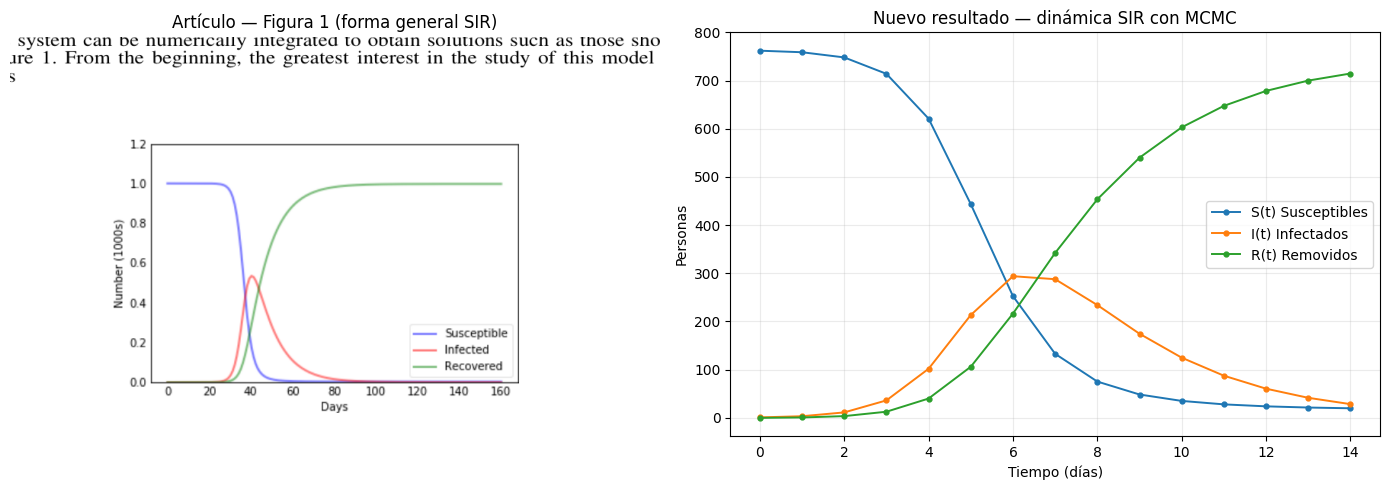

In [14]:
# Comparación de la dinámica SIR: artículo vs. parámetros reajustados.

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

img_sir = mpimg.imread('/mnt/data/articulo_figura1_SIR.png')
axes[0].imshow(img_sir)
axes[0].axis('off')
axes[0].set_title('Artículo — Figura 1 (forma general SIR)')

axes[1].plot(t_datos, S_mejor, marker='o', markersize=3.5, linewidth=1.4, label='S(t) Susceptibles')
axes[1].plot(t_datos, I_mejor, marker='o', markersize=3.5, linewidth=1.4, label='I(t) Infectados')
axes[1].plot(t_datos, R_mejor, marker='o', markersize=3.5, linewidth=1.4, label='R(t) Removidos')
axes[1].set_xlabel('Tiempo (días)')
axes[1].set_ylabel('Personas')
axes[1].set_title('Nuevo resultado — dinámica SIR con MCMC')
axes[1].grid(alpha=0.25)
axes[1].legend()

plt.tight_layout()
plt.show()

**Interpretación:** la gráfica de la izquierda muestra la forma general de las soluciones SIR presentada en el artículo. La gráfica de la derecha muestra las tres curvas $S(t)$, $I(t)$ y $R(t)$ obtenidas con los parámetros reajustados mediante MCMC. Para facilitar la lectura visual, las tres líneas del reajuste se dejaron **más delgadas**.

## 14. Comparación numérica con valores reportados

El artículo menciona como referencia los valores obtenidos por Murray:

In [15]:
print("Comparación de parámetros")
print(f"MCMC - mejor a: {mejor_a:.6f}    mejor b: {mejor_b:.6f}")
print("Murray:          a: 0.002180    b: 0.448500")
print("Artículo (GA):   a: 0.002050    b: 0.435520")


Comparación de parámetros
MCMC - mejor a: 0.002161    mejor b: 0.423630
Murray:          a: 0.002180    b: 0.448500
Artículo (GA):   a: 0.002050    b: 0.435520
